<a href="https://pulse.simudyne.com"><img src="_notebook_assets/Simudyne_Symbol_Logotype_BLUE_RGB.png" width="320" alt="Simudyne"></a>

# Pulse FM Execution Algorithms

> **Simudyne Pulse · Production** — runs with the Simudyne-[Pulse](https://pulse.simudyne.com) SDK. 

Place an execution algorithm in a generated market and measure what it cost.

A job with an algo runs two sims per draw — a **baseline**, and the same market with your orders in it. The seeds match, so the pair differs only by the orders: the difference *is* the impact, not noise.

📖 **Docs:** [Execution algorithms](https://pulse.simudyne.com/docs/simulations#exec-algos) · [Download data](https://pulse.simudyne.com/docs/available-data) · [Foundation models](https://pulse.simudyne.com/docs/foundation-models)

### Setup

`pip install simudyne-pulse` and set your key — `export SIMUDYNE_API_KEY=pk_live_...`, or pass
`PulseABM(api_key=...)`. Keys come from your [account page](https://pulse.simudyne.com/docs/api-keys); see
[Authentication](https://pulse.simudyne.com/docs/authentication).

A production run is a **job**: `run()` returns at once with a `job_id`, the model runs on
Pulse's compute, and `wait()` below polls it every 20 seconds until it finishes.

In [1]:
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import clear_output
from simudyne import PulseABM

client = PulseABM()   # reads SIMUDYNE_API_KEY; points at production by default


def wait(job_id, every=20):
    """Poll a job until every run has finished and its results can be read."""
    start = time.time()
    while True:
        status = client.simulation.get_job_status(job_id)
        clear_output(wait=True)
        note = "" if status["is_complete"] else status.get("message") or ""
        print(f"{job_id}  {time.time() - start:4.0f}s  {status['status_summary']}  {note}")
        if status["is_complete"]:
            sims = client.simulation.get_job_results(job_id)["simulations"]
            if all(s.get("metrics") or s["status"] in ("error", "failed") for s in sims):
                break
        time.sleep(every)
    if status["has_errors"]:
        print(client.simulation.get_job_logs(job_id)[-2000:])
    return status


def generated(sim_id):
    """The model's own rows: sim_data.parquet minus the real warm-start context."""
    book = client.simulation.get_sim_data(sim_id)
    segments = client.simulation.get_sim_metrics(sim_id)["segments"]
    return pl.concat([book.slice(a, b - a) for a, b in (s["generated"] for s in segments)])


def mid(frame):
    return frame.select("timestamp", mid=(pl.col("bid_price_1") + pl.col("ask_price_1")) / 2)


def style(ax, title, ylabel="mid"):
    ax.set(title=title, ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.margins(x=0)

An algo needs a real market day — the model's test day cannot carry one — so name it.
One algo per job on a foundation model.

In [2]:
print("Models available to you:", [m["production_name"] for m in client.fm.models()["models"]])
MODEL = "flow-lse-1-54M"   # the public LSE model
MARKET = dict(symbol="TSCO", cal_date="2025-09-01", provider="bmll", exchange="lse")


def arm(sim_id):
    """'baseline', or the algo that sim carried — it is the second-last field of the sim_id."""
    return "baseline" if sim_id.split(":")[-2] == "baseline" else "execution"


COLOUR = {"baseline": "tab:blue", "execution": "tab:red"}


def plot_arms(sim_ids, ax):
    for sim_id in sim_ids:
        m = mid(generated(sim_id))
        ax.plot(m["timestamp"], m["mid"], color=COLOUR[arm(sim_id)], lw=1.6, alpha=0.9)
    for name, colour in COLOUR.items():
        ax.plot([], [], color=colour, label=name)
    ax.legend()


def first_exec(sim_ids):
    return next(s for s in sim_ids if arm(s) == "execution")

Models available to you: ['flow-hkex-1-100M', 'flow-lse-1-100M', 'flow-lse-1-54M']


## 1. TWAP — slice evenly over the clock

| Field | |
|---|---|
| `side` | `buy` or `sell` |
| `order_size` | the parent order, in **lots** |
| `horizon` | how long to work it, in seconds |
| `frequency` | seconds between child orders — 360/20 gives 18 |
| `start_time` | clock time on the trading day |
| `random_offset` | jitter each child so it is not a metronome |

The run covers ten minutes from the open, `08:00–08:10`. The orders start at `08:02` — two
minutes of the model's own book first — and finish at `08:08`, leaving time to watch the impact
settle. Orders outside the generated window are never seen by the model.
Every field: [Execution algorithms](https://pulse.simudyne.com/docs/simulations#exec-algos).

In [3]:
twap = {
    "type":          "twap",
    "side":          "buy",
    "order_size":    20000,       # lots
    "start_time":    "08:02:00",
    "horizon":       360,         # six minutes
    "frequency":     20,          # a child every 20 s -> 18 orders
    "random_offset": True,
}

job = client.simulation.run(engine="fm", model_id=MODEL, **MARKET,
                            duration_minutes=10, seed=11, exec_algos=[twap])
status = wait(job["job_id"])

b216a283-16c0-4df2-9896-94a124085eb4   146s  {'complete': 2}  


## 2. One run, two sims

One sim is the baseline, one carries the orders — the `sim_id` says which:

In [4]:
for sim_id in job["sim_ids"]:
    print(f"{arm(sim_id):<10}", sim_id)

baseline   bmll:lse:TSCO:2025-09-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:0800-0810:78603398:normal_99914b93:baseline:0000
execution  bmll:lse:TSCO:2025-09-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:0800-0810:78603398:normal_99914b93:twap_7422b114:0000


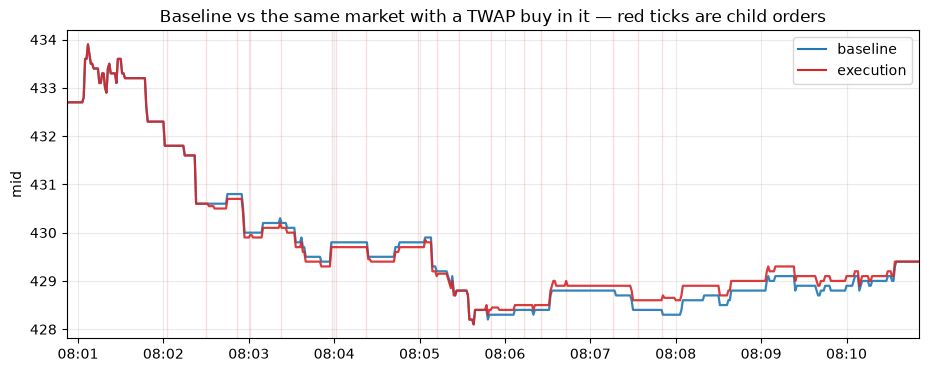

In [5]:
exec_id = first_exec(job["sim_ids"])
schedule = client.simulation.get_sim_data(exec_id, "exec_schedule.parquet")

fig, ax = plt.subplots(figsize=(11, 4))
plot_arms(job["sim_ids"], ax)
for t in schedule["time"]:
    ax.axvline(t, color="tab:red", alpha=0.15, lw=1)
style(ax, "Baseline vs the same market with a TWAP buy in it — red ticks are child orders")

What it cost is **`exec_results.parquet`** — market impact, slippage and risk over the fills,
in lots. Only the arm that carried orders has one; `list_sim_files()` says so before you ask.

In [6]:
for sim_id in job["sim_ids"]:
    print(f"{arm(sim_id):<10} has exec_results:", client.simulation.list_sim_files(sim_id)["has_exec_results"])

client.simulation.get_sim_data(exec_id, "exec_results.parquet")

baseline   has exec_results: False


execution  has exec_results: True


algo_name,order_size,side,horizon,market_slippage,market_risk,market_impact,executed_vol,error,n_runs,market_slippage_mean,market_slippage_std,market_risk_mean,market_risk_std,market_impact_mean,market_impact_std,executed_vol_mean,executed_vol_std,fill_rate_pct_mean
str,f64,str,str,f64,f64,f64,f64,null,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""twap""",20000.0,"""buy""","""6 min""",-4.034203,-4.075839,0.041635,19091.744812,null,1,-4.034203,NaN,-4.075839,NaN,0.041635,NaN,19091.744812,NaN,95.458724


In [7]:
schedule.head()   # exec_schedule.parquet: every child order, time and quantity

time,quantity
datetime[μs],f64
2025-09-01 08:02:02.571404,1111.0
2025-09-01 08:02:29.985557,1111.0
2025-09-01 08:02:52.029967,1111.0
2025-09-01 08:03:00.573780,1111.0
2025-09-01 08:03:22.958522,1111.0


## 3. VWAP, many times — the cost is a distribution

Same fields as TWAP, but the curve follows the day's traded volume. Three draws give three
seed-identical pairs, so `exec_results` carries a mean and a standard deviation.

In [8]:
N_RUNS = 3

vwap = {
    "type":          "vwap",
    "side":          "buy",
    "order_size":    20000,
    "start_time":    "08:02:00",
    "horizon":       360,
    "frequency":     20,
    "random_offset": False,
}

job_vwap = client.simulation.run(engine="fm", model_id=MODEL, **MARKET,
                                 duration_minutes=10, n_runs=N_RUNS, seed=11, exec_algos=[vwap])
status = wait(job_vwap["job_id"])

8c2401c2-0a95-49a7-90ab-35bbc00ce167   442s  {'complete': 6}  


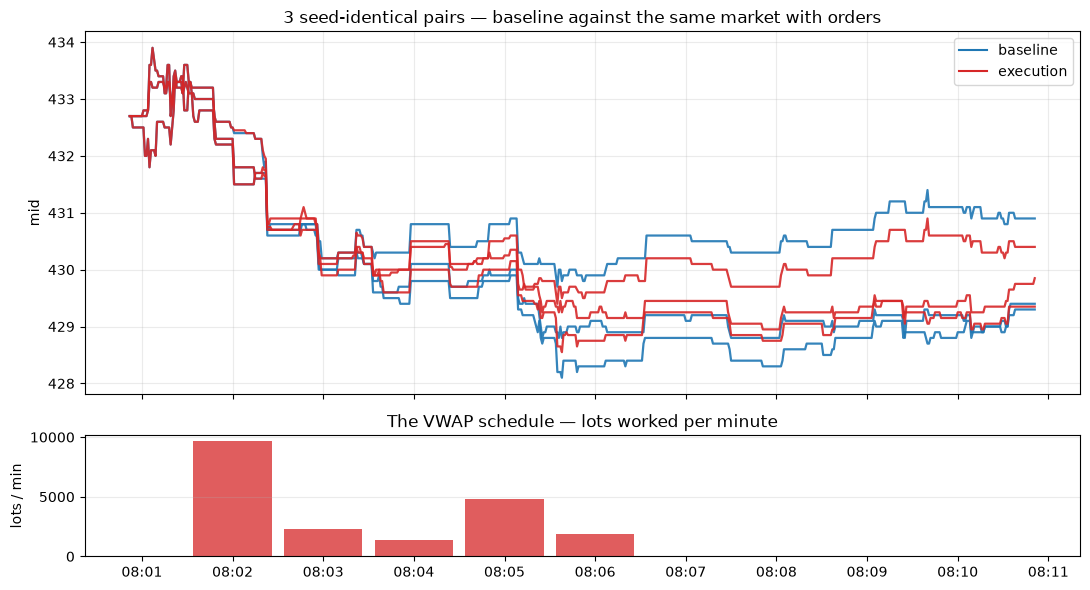

In [9]:
exec_id = first_exec(job_vwap["sim_ids"])
by_min = client.simulation.get_sim_data(exec_id, "schedule_by_min.parquet")

fig, (ax, bx) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
plot_arms(job_vwap["sim_ids"], ax)
style(ax, f"{N_RUNS} seed-identical pairs — baseline against the same market with orders")

bx.bar(by_min["time"], by_min["quantity"], width=0.0006, color="tab:red", alpha=0.75)
bx.set(title="The VWAP schedule — lots worked per minute", ylabel="lots / min")
bx.grid(alpha=0.25, axis="y")
plt.tight_layout()

In [10]:
client.simulation.get_sim_data(exec_id, "exec_results.parquet")

algo_name,order_size,side,horizon,market_slippage,market_risk,market_impact,executed_vol,error,n_runs,market_slippage_mean,market_slippage_std,market_risk_mean,market_risk_std,market_impact_mean,market_impact_std,executed_vol_mean,executed_vol_std,fill_rate_pct_mean
str,f64,str,str,f64,f64,f64,f64,null,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""vwap""",20000.0,"""buy""","""6 min""",-3.405579,-3.667709,0.262129,13624.418945,null,3,-3.160028,0.215013,-3.289119,0.422913,0.129091,0.262049,14310.366043,991.340731,71.55183


## 4. A schedule of your own

`css` takes the times and sizes directly, so you can run any curve — the `orders` mapping
replaces `order_size`, `horizon` and `start_time`.

**A child order is clipped to the liquidity that is there**, so size alone buys you nothing past
the touch. What moves the mid is *rate*: this schedule front-loads by going faster — every 10
seconds for two minutes, then every 30 — never by making each slice bigger.

In [11]:
from datetime import datetime, timedelta

start = datetime.fromisoformat(f"{MARKET['cal_date']}T08:02:00")
orders = {(start + timedelta(seconds=10 * i)).isoformat(): 2000 for i in range(12)}
orders |= {(start + timedelta(minutes=2, seconds=30 * i)).isoformat(): 2000 for i in range(8)}

css = {"type": "css", "side": "buy", "orders": orders}

job_css = client.simulation.run(engine="fm", model_id=MODEL, **MARKET,
                                duration_minutes=10, n_runs=2, seed=11, exec_algos=[css])
status = wait(job_css["job_id"])

bbcc65d4-d2ab-44a1-8b1a-13930e5baa28   294s  {'complete': 4}  


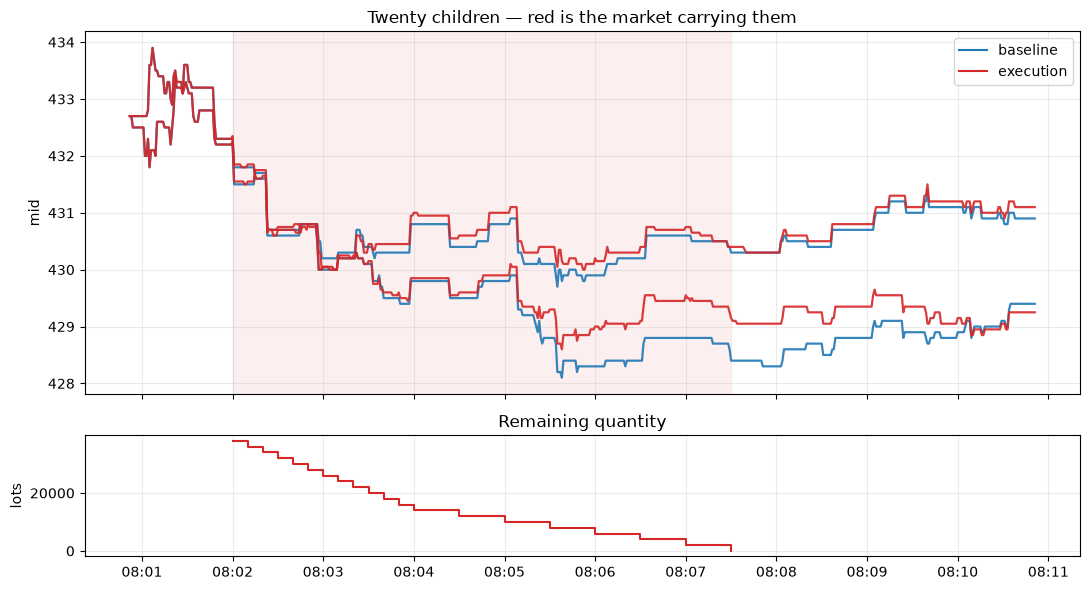

In [12]:
schedule = client.simulation.get_sim_data(first_exec(job_css["sim_ids"]), "exec_schedule.parquet")
remaining = schedule.sort("time").select("time", left=pl.col("quantity").sum() - pl.col("quantity").cum_sum())

fig, (ax, bx) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
plot_arms(job_css["sim_ids"], ax)
ax.axvspan(schedule["time"].min(), schedule["time"].max(), color="tab:red", alpha=0.07)
style(ax, "Twenty children — red is the market carrying them")

bx.step(remaining["time"], remaining["left"], where="post", color="tab:red")
bx.set(title="Remaining quantity", ylabel="lots")
bx.grid(alpha=0.25)
plt.tight_layout()

---

- **One algo per job** on a foundation model — each doubles the sims.
- **`order_size` is in lots**, not shares.
- **A child is capped by the book, so schedule by rate.**
- `exec_results.parquet`, `exec_schedule.parquet` and `schedule_by_min.parquet` exist only for the
  execution arm — check `list_sim_files()` first.

More: [Execution algorithms](https://pulse.simudyne.com/docs/simulations#exec-algos) · [Output files](https://pulse.simudyne.com/docs/available-data)